In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Amazon Prime EDA Project Started!")

Amazon Prime EDA Project Started!


In [2]:
# Load the datasets

titles = pd.read_csv("titles.csv")
credits = pd.read_csv("credits.csv")

print("Titles Dataset Loaded Successfully!")
print("Credits Dataset Loaded Successfully!")

Titles Dataset Loaded Successfully!
Credits Dataset Loaded Successfully!


In [3]:
print("Titles Dataset Shape:", titles.shape)
print("Credits Dataset Shape:", credits.shape)

display(titles.head())

Titles Dataset Shape: (9871, 15)
Credits Dataset Shape: (124235, 5)


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6


In [4]:
# Check column names and data types

print("TITLES DATASET")
print(titles.info())

print("\nMISSING VALUES IN TITLES")
print(titles.isnull().sum())

print("\nCREDITS DATASET")
print(credits.info())

print("\nMISSING VALUES IN CREDITS")
print(credits.isnull().sum())

TITLES DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: flo

In [5]:
# Missing values summary

print("MISSING VALUES IN TITLES")
titles_missing = titles.isnull().sum()
print(titles_missing[titles_missing > 0])

print("\nMISSING VALUES IN CREDITS")
credits_missing = credits.isnull().sum()
print(credits_missing[credits_missing > 0])

MISSING VALUES IN TITLES
description           119
age_certification    6487
seasons              8514
imdb_id               667
imdb_score           1021
imdb_votes           1031
tmdb_popularity       547
tmdb_score           2082
dtype: int64

MISSING VALUES IN CREDITS
character    16287
dtype: int64


In [6]:
# Check duplicate records

print("Duplicate titles:", titles.duplicated().sum())

print("Duplicate title IDs:", titles["id"].duplicated().sum())

print("Duplicate credit rows:", credits.duplicated().sum())

Duplicate titles: 3
Duplicate title IDs: 3
Duplicate credit rows: 56


In [7]:
# Display duplicate title records

duplicate_titles = titles[titles["id"].duplicated(keep=False)]

display(duplicate_titles)

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
479,tm89134,The Gunman From Bodie,MOVIE,The Rough Riders are after a gang of rustlers....,1941,NaN,62,['western'],['US'],NaN,tt0033683,5.9,133.0,0.991,7.0
480,tm89134,The Gunman From Bodie,MOVIE,The Rough Riders are after a gang of rustlers....,1941,NaN,62,['western'],['US'],NaN,tt0033683,5.9,133.0,0.991,7.0
718,tm66674,Dynamite,MOVIE,Two members of a dynamite crew--a rugged veter...,1949,NaN,68,"['drama', 'crime']",['US'],NaN,tt0039343,5.0,24.0,0.841,NaN
719,tm137955,Broken Dreams,MOVIE,Medical intern Robert Morley is distraught aft...,1933,NaN,68,"['drama', 'romance']",['US'],NaN,tt0023849,5.8,74.0,0.600,NaN
720,tm66674,Dynamite,MOVIE,Two members of a dynamite crew--a rugged veter...,1949,NaN,68,"['drama', 'crime']",['US'],NaN,tt0039343,5.0,24.0,0.841,NaN
722,tm137955,Broken Dreams,MOVIE,Medical intern Robert Morley is distraught aft...,1933,NaN,68,"['drama', 'romance']",['US'],NaN,tt0023849,5.8,74.0,0.600,NaN


In [8]:
# Remove duplicate records

titles_clean = titles.drop_duplicates(subset="id", keep="first").copy()

credits_clean = credits.drop_duplicates().copy()

# Check the cleaned datasets

print("Original titles:", titles.shape)
print("Cleaned titles:", titles_clean.shape)

print("\nOriginal credits:", credits.shape)
print("Cleaned credits:", credits_clean.shape)

print("\nRemaining duplicate title IDs:", titles_clean["id"].duplicated().sum())
print("Remaining duplicate credit rows:", credits_clean.duplicated().sum())

Original titles: (9871, 15)
Cleaned titles: (9868, 15)

Original credits: (124235, 5)
Cleaned credits: (124179, 5)

Remaining duplicate title IDs: 0
Remaining duplicate credit rows: 0


In [9]:
# Save cleaned datasets

titles_clean.to_csv("titles_cleaned.csv", index=False)
credits_clean.to_csv("credits_cleaned.csv", index=False)

print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!


## 1. Movies vs TV Shows Distribution

Movies and TV Shows Count:
type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64


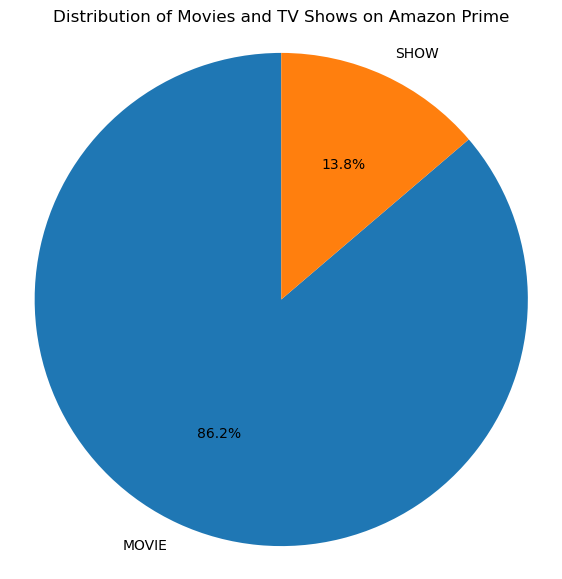

In [2]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
titles_clean = pd.read_csv("titles_cleaned.csv")

# Count Movies and TV Shows
type_counts = titles_clean["type"].value_counts()

print("Movies and TV Shows Count:")
print(type_counts)

# Create a pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Movies and TV Shows on Amazon Prime")
plt.axis("equal")
plt.show()

### Observation

- Amazon Prime has 8,511 movies and 1,357 TV shows.
- Movies account for 86.2% of the total content.
- TV shows account for only 13.8%.
- This shows that Amazon Prime has a much larger collection of movies than TV shows.

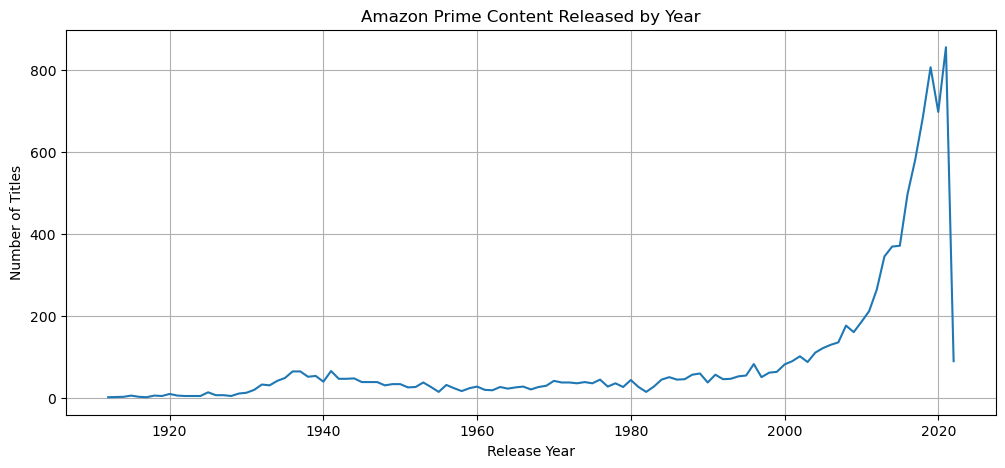

In [3]:
# Count content released each year

year_counts = titles_clean["release_year"].value_counts().sort_index()

# Create a line chart

plt.figure(figsize=(12, 5))

plt.plot(year_counts.index, year_counts.values)

plt.title("Amazon Prime Content Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.show()

Top 10 Genres:
drama            4762
comedy           2987
thriller         2119
action           1820
romance          1751
crime            1250
documentation    1096
horror           1065
family            751
european          712
dtype: int64


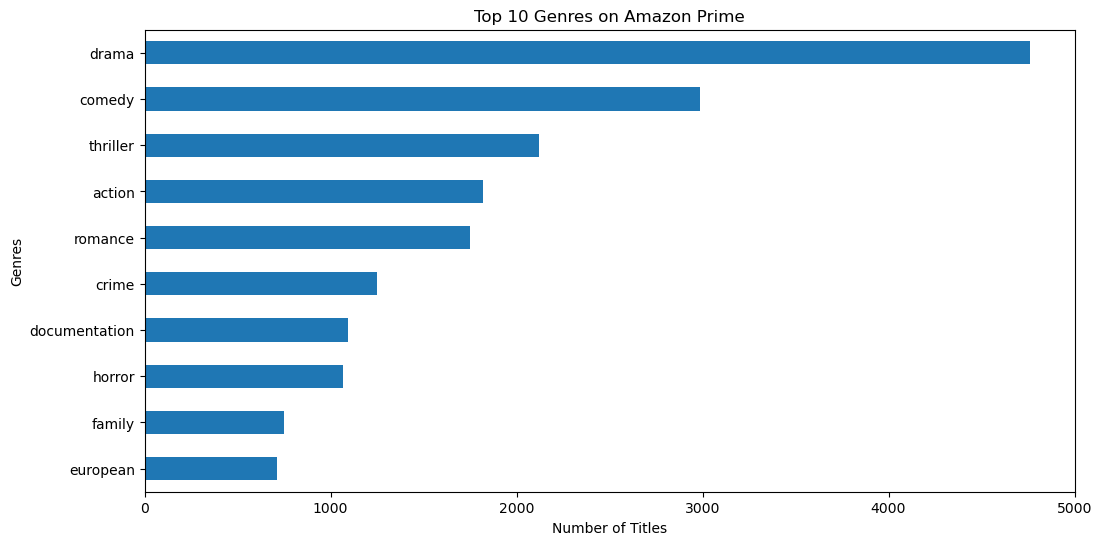

In [4]:
# Find the top 10 genres

import ast
from collections import Counter

genre_list = []

for value in titles_clean["genres"].dropna():
    try:
        genres = ast.literal_eval(value)
        if isinstance(genres, list):
            genre_list.extend(genres)
    except (ValueError, SyntaxError):
        pass

genre_counts = Counter(genre_list)

top_genres = pd.Series(dict(genre_counts.most_common(10)))

print("Top 10 Genres:")
print(top_genres)

# Create a bar chart

plt.figure(figsize=(12, 6))

top_genres.sort_values().plot(kind="barh")

plt.title("Top 10 Genres on Amazon Prime")
plt.xlabel("Number of Titles")
plt.ylabel("Genres")
plt.show()

Top 10 Production Countries:
US    5331
IN    1072
GB     928
CA     530
FR     250
JP     197
AU     173
DE     172
IT     143
CN     143
dtype: int64


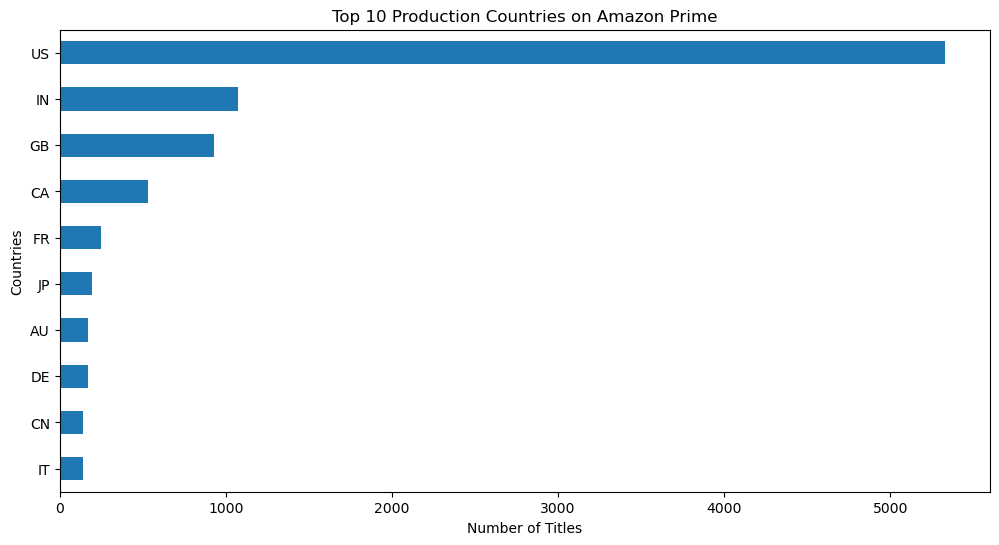

In [5]:
# Find the top 10 production countries

import ast
from collections import Counter

country_list = []

for value in titles_clean["production_countries"].dropna():
    try:
        countries = ast.literal_eval(value)
        if isinstance(countries, list):
            country_list.extend(countries)
    except (ValueError, SyntaxError):
        pass

country_counts = Counter(country_list)

top_countries = pd.Series(dict(country_counts.most_common(10)))

print("Top 10 Production Countries:")
print(top_countries)

# Create a bar chart

plt.figure(figsize=(12, 6))

top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Production Countries on Amazon Prime")
plt.xlabel("Number of Titles")
plt.ylabel("Countries")
plt.show()

Age Certification Distribution:
age_certification
R        1249
PG-13     588
PG        582
G         269
TV-MA     217
TV-14     188
TV-PG      91
TV-Y       78
TV-G       57
TV-Y7      52
NC-17      13
Name: count, dtype: int64


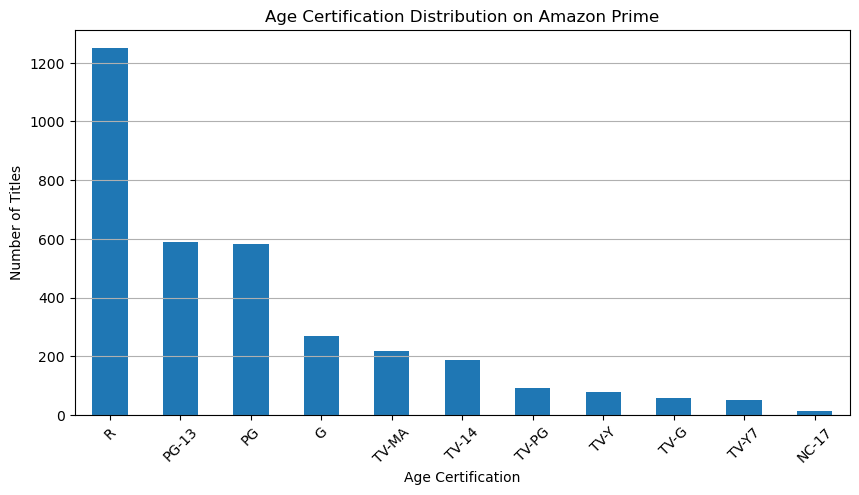

In [6]:
# Count age certifications

certification_counts = titles_clean["age_certification"].value_counts()

print("Age Certification Distribution:")
print(certification_counts)

# Create a bar chart

plt.figure(figsize=(10, 5))

certification_counts.plot(kind="bar")

plt.title("Age Certification Distribution on Amazon Prime")
plt.xlabel("Age Certification")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

IMDb Ratings Summary:
count    8847.000000
mean        5.976534
std         1.344028
min         1.100000
25%         5.100000
50%         6.100000
75%         6.900000
max         9.900000
Name: imdb_score, dtype: float64


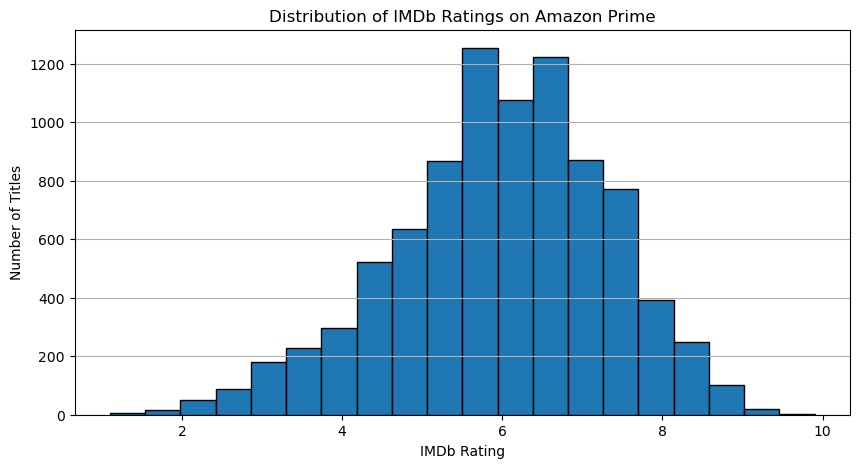

In [7]:
# Analyse IMDb ratings

imdb_ratings = titles_clean["imdb_score"].dropna()

print("IMDb Ratings Summary:")
print(imdb_ratings.describe())

# Create a histogram

plt.figure(figsize=(10, 5))

plt.hist(imdb_ratings, bins=20, edgecolor="black")

plt.title("Distribution of IMDb Ratings on Amazon Prime")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Titles")
plt.grid(axis="y")

plt.show()

In [8]:
# Hypothesis Test 1: Compare IMDb ratings

from scipy.stats import ttest_ind

movies = titles_clean[
    (titles_clean["type"] == "MOVIE") &
    (titles_clean["imdb_score"].notna())
]["imdb_score"]

tv_shows = titles_clean[
    (titles_clean["type"] == "SHOW") &
    (titles_clean["imdb_score"].notna())
]["imdb_score"]

# Perform independent t-test

t_stat, p_value = ttest_ind(movies, tv_shows, equal_var=False)

print("Average Movie IMDb Rating:", movies.mean())
print("Average TV Show IMDb Rating:", tv_shows.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: There is a statistically significant difference.")
else:
    print("Result: There is no statistically significant difference.")

Average Movie IMDb Rating: 5.803202707980732
Average TV Show IMDb Rating: 7.1183533447684395
T-statistic: -35.32840470394638
P-value: 3.0300216346272915e-203
Result: There is a statistically significant difference.


In [9]:
from scipy.stats import ttest_ind

before_2010 = titles_clean[
    (titles_clean["release_year"] < 2010) &
    (titles_clean["imdb_score"].notna())
]["imdb_score"]

after_2010 = titles_clean[
    (titles_clean["release_year"] >= 2010) &
    (titles_clean["imdb_score"].notna())
]["imdb_score"]

t_stat, p_value = ttest_ind(
    before_2010,
    after_2010,
    equal_var=False
)

print("Average IMDb Rating before 2010:", before_2010.mean())
print("Average IMDb Rating from 2010 onwards:", after_2010.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: There is a statistically significant difference.")
else:
    print("Result: There is no statistically significant difference.")

Average IMDb Rating before 2010: 5.954861681731032
Average IMDb Rating from 2010 onwards: 5.991762894534257
T-statistic: -1.314338012992798
P-value: 0.18876744832029388
Result: There is no statistically significant difference.


In [10]:
from scipy.stats import pearsonr

correlation_data = titles_clean[
    ["imdb_score", "imdb_votes"]
].dropna()

correlation, p_value = pearsonr(
    correlation_data["imdb_score"],
    correlation_data["imdb_votes"]
)

print("Correlation:", correlation)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: There is a statistically significant relationship.")
else:
    print("Result: There is no statistically significant relationship.")

Correlation: 0.16587934689229283
P-value: 1.5072443305642509e-55
Result: There is a statistically significant relationship.


## Business Objective

The main objective of this project is to analyse Amazon Prime Video movies and TV shows using Exploratory Data Analysis (EDA).

The project aims to:

1. Understand the distribution of movies and TV shows.
2. Identify the most common genres and production countries.
3. Analyse content released over different years.
4. Study age certification and IMDb ratings.
5. Compare ratings of movies and TV shows.
6. Identify patterns and relationships in the dataset.
7. Generate useful insights to understand the Amazon Prime Video content catalogue.

## Conclusion

In this project, Exploratory Data Analysis (EDA) was performed on the Amazon Prime Video movies and TV shows dataset.

The analysis helped us understand the content distribution, release years, popular genres, production countries, age certifications and IMDb ratings.

The major findings are:

1. Movies make up a larger portion of the catalogue than TV shows.
2. The dataset contains content from different release years and production countries.
3. Different genres are available on Amazon Prime Video.
4. TV shows have a higher average IMDb rating than movies in this dataset.
5. There is no statistically significant difference in average IMDb ratings between content released before 2010 and from 2010 onwards.

Overall, this project helped us understand how data analysis and visualisation can be used to identify patterns, trends and useful insights from a real-world dataset.

# **Project Name**    -



# Project Details

**Project Name:** Amazon Prime Video Movies and TV Shows – Exploratory Data Analysis

**Project Type:** EDA

**Contribution:** Individual

**Project Domain:** Entertainment and Data Analytics

**Dataset:** Amazon Prime Video Movies and TV Shows

##### **Project Type**    - EDA/Regression/Classification/Unsupervised
##### **Contribution**    - Individual/Team
##### **Team Member 1 -**
##### **Team Member 2 -**
##### **Team Member 3 -**
##### **Team Member 4 -**

In [ ]:
# Project Details

**Project Name:** Amazon Prime Video Movies and TV Shows – Exploratory Data Analysis (EDA)

**Project Type:** Exploratory Data Analysis

**Contribution:** Individual

**Project Domain:** Entertainment and Data Analytics

**Dataset:** Amazon Prime Video Movies and TV Shows

# **Project Summary -**

Write the summary here within 500-600 words.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


**Write Problem Statement Here.**

#### **Define Your Business Objective?**

Answer Here.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries

### Dataset Loading

In [ ]:
# Load Dataset

### Dataset First View

In [ ]:
# Dataset First Look

### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count

### Dataset Information

In [ ]:
# Dataset Info

#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count

#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count

In [ ]:
# Visualizing the missing values

### What did you know about your dataset?

Answer Here

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns

In [ ]:
# Dataset Describe

### Variables Description

Answer Here

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.

## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.

### What all manipulations have you done and insights you found?

Answer Here.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

In [ ]:
# Chart - 1 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 2

In [ ]:
# Chart - 2 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 3

In [ ]:
# Chart - 3 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 4

In [ ]:
# Chart - 4 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 5

In [ ]:
# Chart - 5 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 6

In [ ]:
# Chart - 6 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 7

In [ ]:
# Chart - 7 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 8

In [ ]:
# Chart - 8 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 9

In [ ]:
# Chart - 9 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 10

In [ ]:
# Chart - 10 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 11

In [ ]:
# Chart - 11 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 12

In [ ]:
# Chart - 12 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 13

In [ ]:
# Chart - 13 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 14 - Correlation Heatmap

In [ ]:
# Correlation Heatmap visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

#### Chart - 15 - Pair Plot

In [ ]:
# Pair Plot visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

Answer Here.

# **Conclusion**

Write the conclusion here.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***